In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib
from pathlib import Path
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"
OUT = ROOT / "outputs" / "shap"
OUT.mkdir(parents=True, exist_ok=True)

X_train = pd.read_csv(DATA / "X_train.csv")
X_test = pd.read_csv(DATA / "X_test.csv")

model = joblib.load(
    ROOT / "models" / "best_model.joblib"
)

preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

if not isinstance(classifier, LogisticRegression):
    raise ValueError("This SHAP notebook expects Logistic Regression.")

feature_names = preprocessor.get_feature_names_out()

def transform_data(X):
    values = preprocessor.transform(X)
    if hasattr(values, "toarray"):
        values = values.toarray()
    return pd.DataFrame(values, columns=feature_names)

train_encoded = transform_data(X_train)
test_encoded = transform_data(X_test)

print("SHAP setup completed!")
print("Transformed features:", len(feature_names))

SHAP setup completed!
Transformed features: 30


In [2]:
explainer = shap.LinearExplainer(
    classifier,
    train_encoded
)

shap_values = explainer(test_encoded)

print("SHAP explanations generated!")
print("Samples:", len(shap_values))

Background dataset has 241 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=241 when initializing the masker.


SHAP explanations generated!
Samples: 61


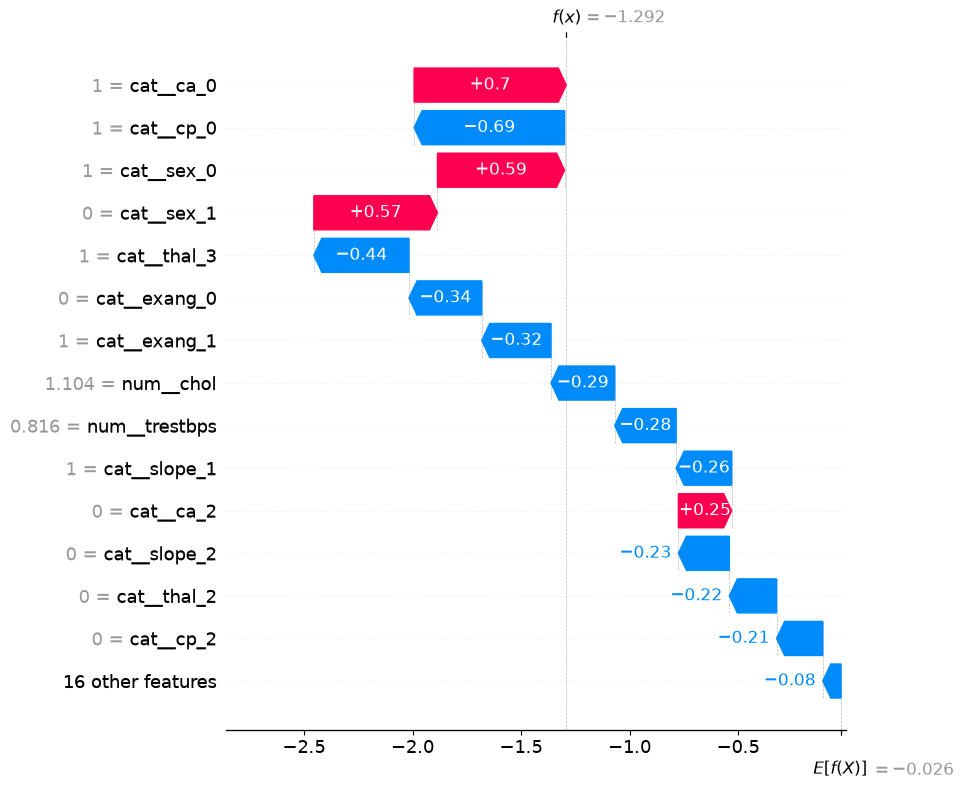

In [3]:
shap.plots.waterfall(
    shap_values[0],
    max_display=15,
    show=False
)

plt.gcf().savefig(
    OUT / "shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

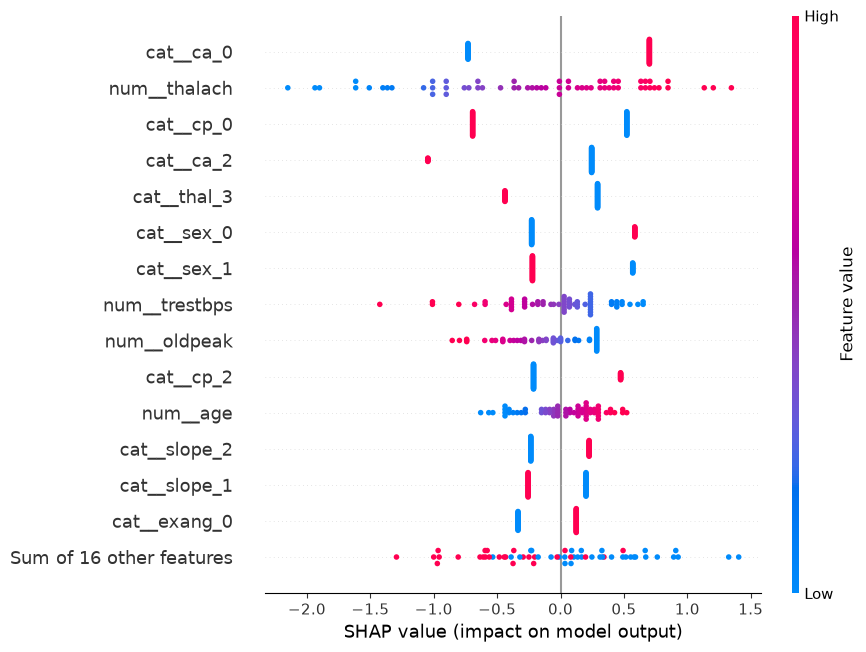

In [4]:
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.gcf().savefig(
    OUT / "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
shap_df = pd.DataFrame(
    shap_values.values,
    columns=feature_names
)

shap_df.to_csv(
    OUT / "shap_values.csv",
    index=False
)

print("SHAP analysis completed!")
print("All results saved successfully!")

SHAP analysis completed!
All results saved successfully!
